# 09G — Competition presentation package

## SAME STOPWATCH. DIFFERENT MOVEMENT.

**Story (reports/milestone09/COMPETITION_STORYBOARD.md).** Opening — two prospects, one forty time. Discovery — where their speed curves differ and whether the difference exceeds measurement uncertainty. Football connection — the speed-change demands NFL games actually contain, and which of them the forty can describe. Decision — the follow-up questions the tool produces. Scientific conclusion — tracking expands the description of movement; repeatability and physical similarity are not proven NFL predictive value. Practical contribution — an evidence-aware tool that makes the extra information usable.

**This notebook computes nothing new.** It reads the application mart, draws the executive visuals, writes one-page intelligence cards for the case-study athletes, and writes two files whose numbers come from the executed tables:

- `reports/milestone09/EXECUTED_NUMBERS.md` — every number the storyboard and the narrative refer to (the authored reports cite it instead of typing numbers);
- `reports/milestone09/CASE_STUDY_GALLERY_EXECUTED.md` — every case with its three views and its figure.

A smoke run writes under `reports/milestone09/_sample` and is labelled.

**Prerequisites.** 09A–09E (09D figures for the gallery), same `RUN_MODE`.

In [1]:
RUN_MODE = 'full'             # 'smoke' | 'full'
SEED = 20261011
FORCE_REBUILD = False
SAVE_TABLES = True
SAVE_FIGURES = True
NUM_WORKERS = 0
MAX_CARDS = 12                # intelligence cards written (athletes of the case studies, in case order)

In [2]:
from nflbdb.data.config import Phase01Config, configure_runtime

cfg = Phase01Config.load()
configure_runtime(cfg)

import polars as pl
from IPython.display import Markdown, display

from nflbdb.data.utils import utc_now
from nflbdb.research.advanced_movement import config as amc
from nflbdb.research.advanced_movement import intelligence_figures as ifg
from nflbdb.research.advanced_movement import milestone09_artifacts as m9
from nflbdb.research.advanced_movement import scouting_interpretation as sin
from nflbdb.research.advanced_movement.artifacts import IntelligenceStore

controls = amc.NotebookControls(run_mode=RUN_MODE, force_rebuild=FORCE_REBUILD, save_figures=SAVE_FIGURES, save_tables=SAVE_TABLES,
                                seed=SEED, num_workers=NUM_WORKERS).validate()
store = IntelligenceStore(cfg, controls)
MART = m9.mart_path(store)
m9.assert_valid(m9.validate_mart(MART))
T, EVID, MANIFEST = m9.load_mart(MART)
OV = MANIFEST['overview']
OUT = store.reports_dir
OUT.mkdir(parents=True, exist_ok=True)
C = T['combine_attempt_curves']

def curves(i):
    return [(g['dist_yd'].to_numpy().astype(float), g['speed'].to_numpy().astype(float)) for _, g in
            C.filter(pl.col('nfl_id') == i).sort('attempt_order', 'frame').partition_by(['attempt_order'], as_dict=True, maintain_order=True).items()]

def band(pos):
    B = T['position_curve_bands'].filter(pl.col('position_group') == pos).sort('dist_yd')
    return {'grid': B['dist_yd'].to_numpy(), 'q10': B['q10'].to_numpy(), 'q50': B['q50'].to_numpy(), 'q90': B['q90'].to_numpy(), 'n': int(B['n_runs'][0])} if B.height else None

label = 'SMOKE — wiring check, numbers are not results' if controls.smoke else 'FULL'
display(Markdown(f'**Run mode: `{controls.run_mode}`** ({label}) · mart built {MANIFEST["built_at"]} · output `{cfg.paths.rel(OUT)}`'))

**Run mode: `full`** (FULL) · mart built 2026-10-14T13:13:05Z · output `reports/milestone09`

## 1 · Executive visuals

1. **Hero** — the first case of type *same forty, different acceleration curve* (or the top-ranked twin pair if that type is absent): stopwatch, tracked curves, difference against uncertainty.
2. **How often twins differ** — distinguishable share per feature against the 5 % chance line.
3. **What NFL games demand** — demand frequency by position.
4. **Where the forty sits in those demands** — matching heatmap.

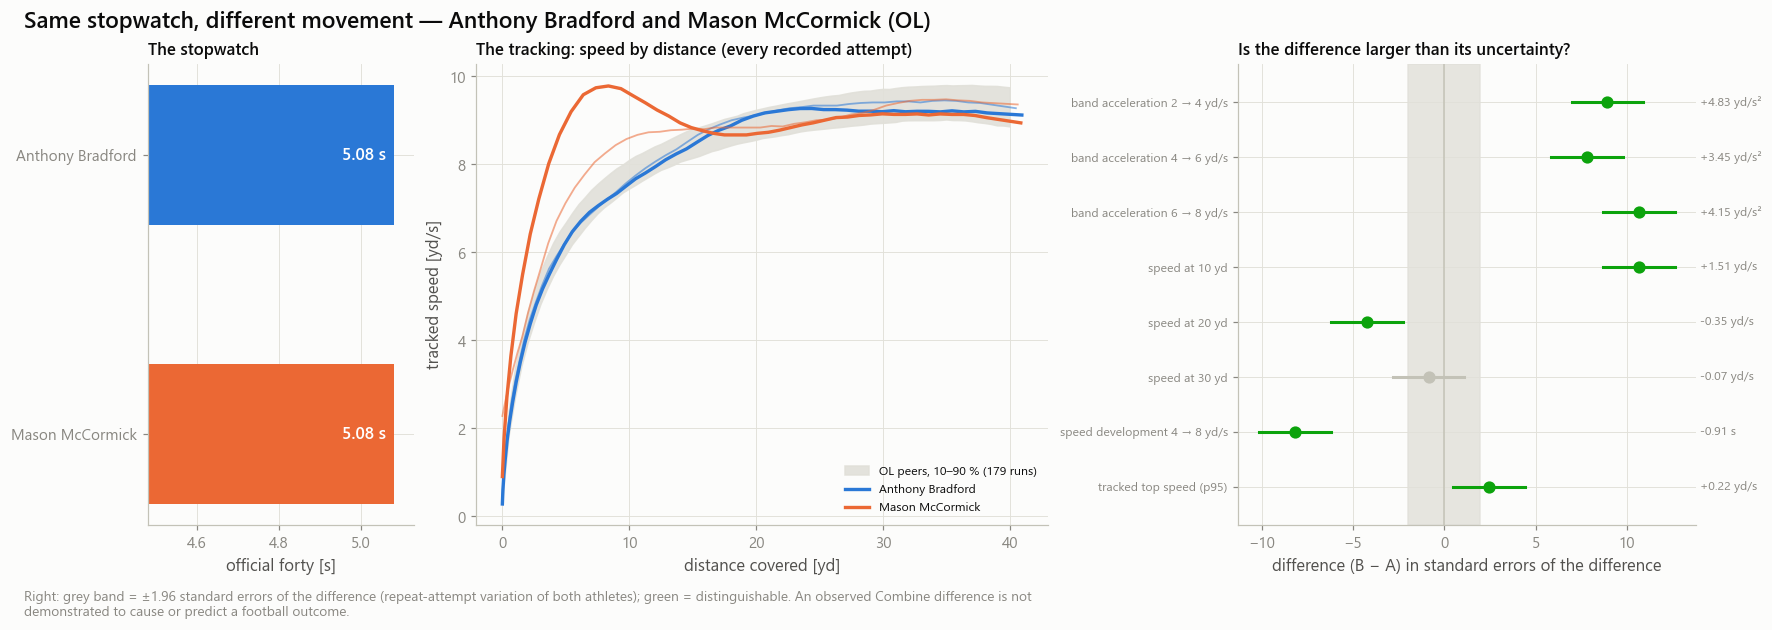

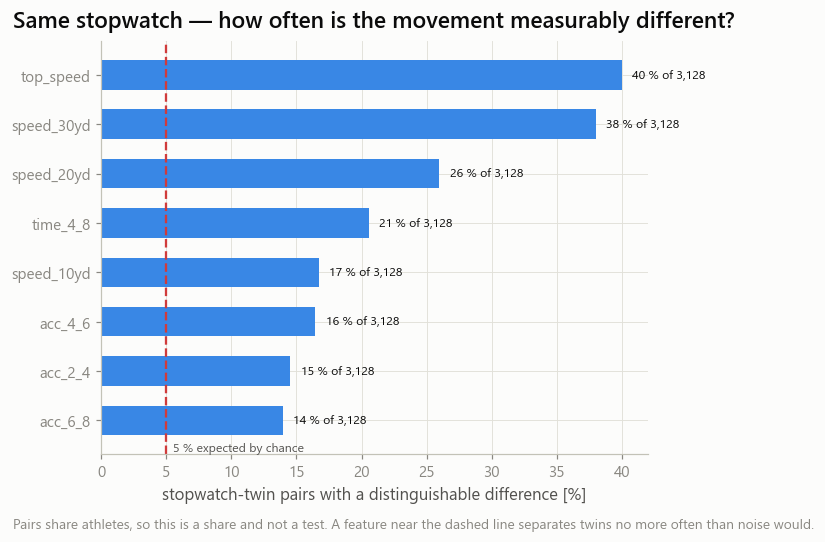

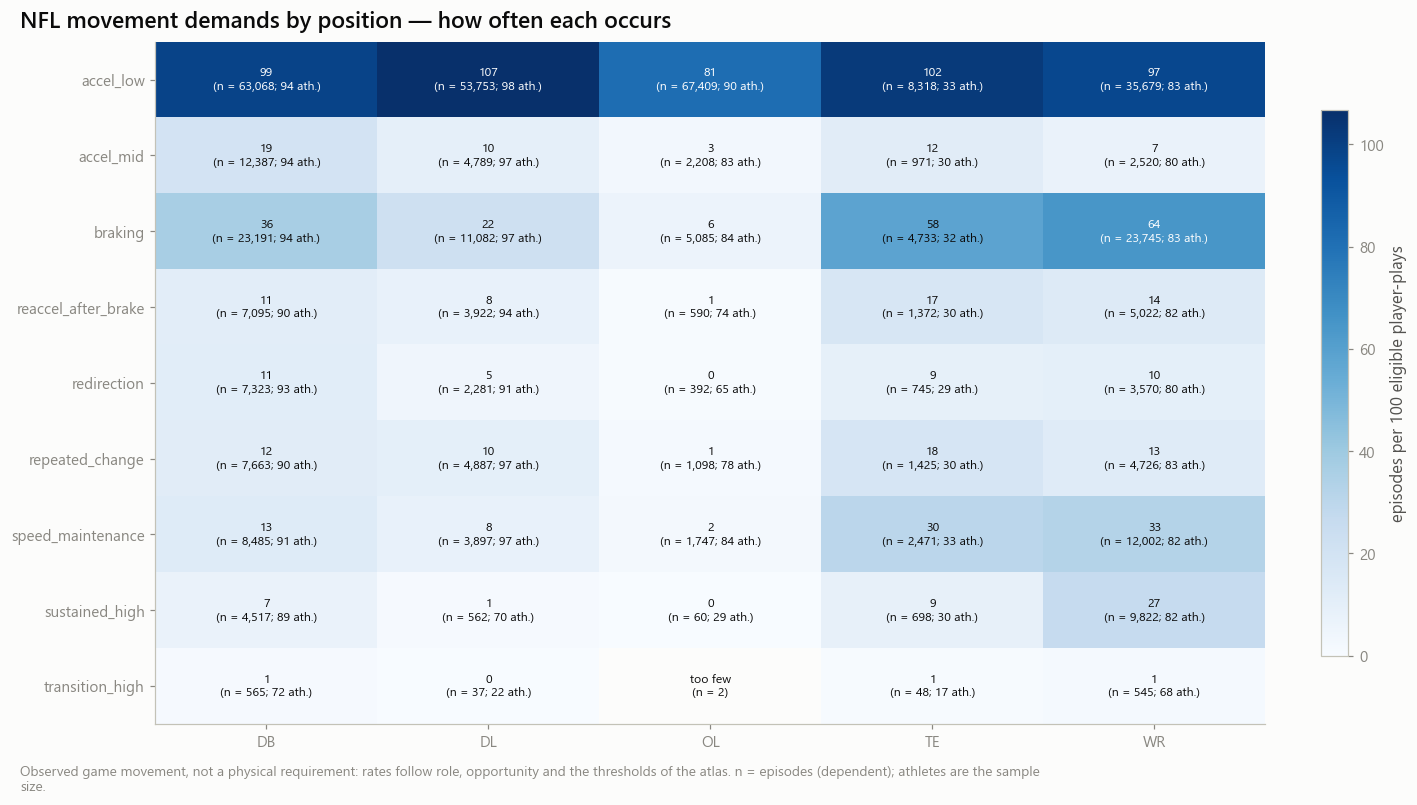

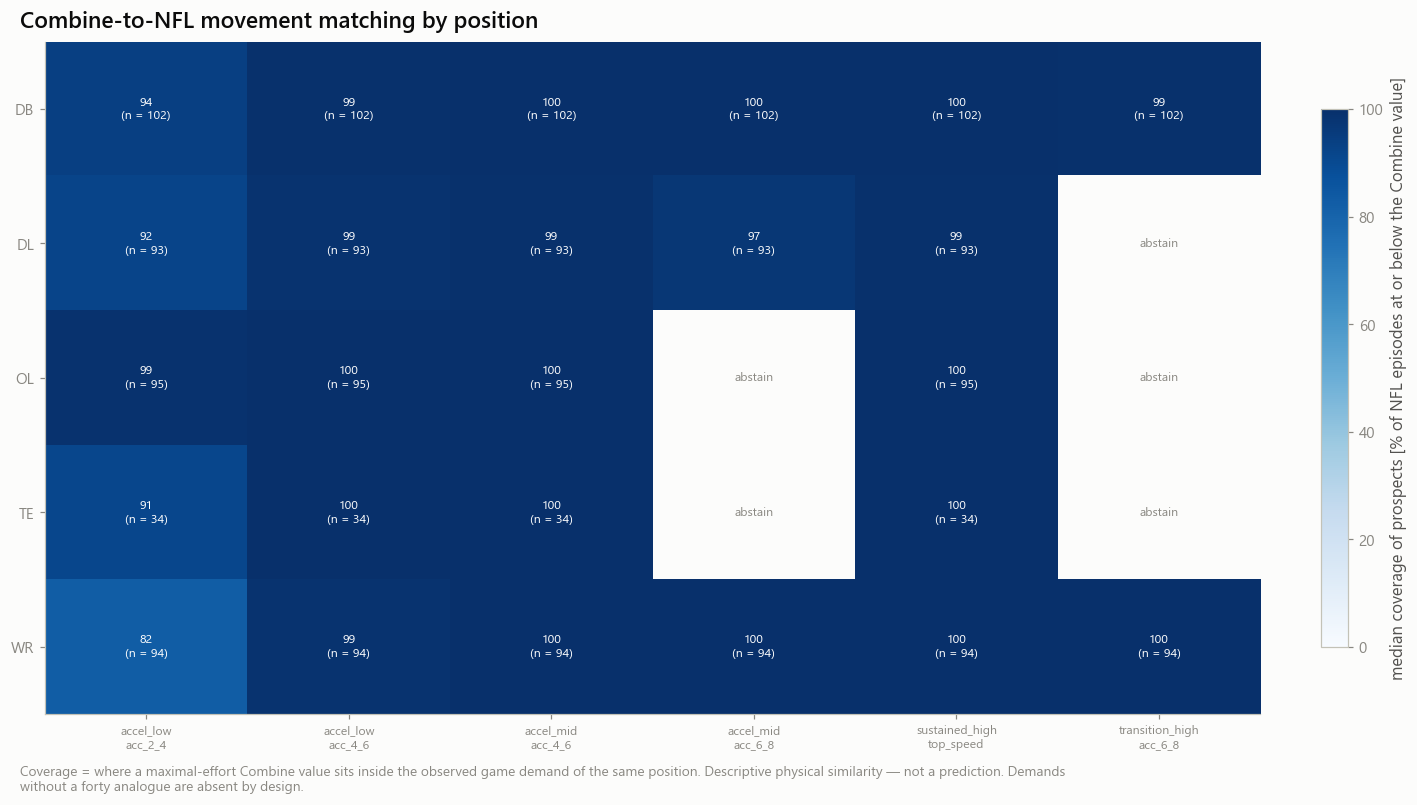

In [3]:
cases = T['scouting_cases']
hero = cases.filter(pl.col('case_type') == 'same_forty_different_curve').head(1)
if hero.height:
    HERO = T['stopwatch_twins'].filter(pl.col('pair_id') == hero['pair_id'][0]).row(0, named=True)
else:
    HERO = T['stopwatch_twins'].sort('max_abs_z', descending=True, nulls_last=True).row(0, named=True)
HD = T['twin_differences'].filter(pl.col('pair_id') == HERO['pair_id']).sort('feature').to_dicts()
store.show(ifg.fig_twin_story(HERO, {HERO['name_a']: curves(HERO['nfl_id_a']), HERO['name_b']: curves(HERO['nfl_id_b'])}, band(HERO['position_group']), HD),
           'AM09G_01_hero_same_stopwatch_different_movement', {}, publication=True, source='application mart', n='two athletes')
store.show(ifg.fig_twin_summary(T['twin_summary']), 'AM09G_02_how_often_twins_differ', {'summary': T['twin_summary']}, publication=True, source='stopwatch_twin_summary',
           n=f'{OV["n_twin_pairs"]:,} pairs (not independent)')
store.show(ifg.fig_demand_frequency(T['nfl_movement_demands']), 'AM09G_03_nfl_movement_demands', {}, publication=True, source='nfl_movement_demands',
           n=f'{OV["n_nfl_episodes"]:,} episodes')
store.show(ifg.fig_similarity_heatmap(T['movement_matching_summary']), 'AM09G_04_forty_inside_nfl_demands', {}, publication=True, source='movement_matching_summary',
           n='prospects per cell annotated')

## 2 · One-page intelligence cards for the case-study athletes

In [4]:
prof = {r['nfl_id']: r for r in T['prospect_profiles'].iter_rows(named=True)}
EV = list(T['feature_evidence'].iter_rows(named=True))
ids = list(dict.fromkeys(i for r in cases.iter_rows(named=True) for i in (r['nfl_id_a'], r['nfl_id_b'])))[:MAX_CARDS]
card_dir = OUT / 'cards'
card_dir.mkdir(parents=True, exist_ok=True)
TW = T['stopwatch_twins']
for i in ids:
    mine = []
    for r in TW.filter((pl.col('nfl_id_a') == i) | (pl.col('nfl_id_b') == i)).sort('max_abs_z', descending=True, nulls_last=True).iter_rows(named=True):
        a_is_me = r['nfl_id_a'] == i
        mine.append({**r, 'other_name': r['name_b'] if a_is_me else r['name_a'], 'd_forty': r['d_forty'] if a_is_me else -r['d_forty']})
    met = T['prospect_metrics'].filter(pl.col('nfl_id') == i).sort('feature').to_dicts()
    mat = T['movement_similarity_matrix'].filter(pl.col('nfl_id') == i).to_dicts()
    sections = sin.prospect_report(prof[i], met, mine, mat, EV)
    fig = ifg.fig_intelligence_card(prof[i], met, mine, mat, curves(i), band(prof[i]['position_group']), sections)
    if controls.save_tables:
        fig.savefig(card_dir / f'intelligence_card_{i}.pdf')
        fig.savefig(card_dir / f'intelligence_card_{i}.png', dpi=200)
    import matplotlib.pyplot as plt
    plt.close(fig)
print(f'{len(ids)} intelligence card(s) written to {cfg.paths.rel(card_dir)}' if controls.save_tables else 'SAVE_TABLES is False: no card written')

12 intelligence card(s) written to reports/milestone09/cards


## 3 · Executed numbers and the case-study gallery

Every number below is read from the mart (and, for the earlier milestones, from the 08B.6 evidence claims carried in it).

In [5]:
claims = {c['claim_id']: c for c in EVID.get('evidence_claims_08b6', [])}
summ = T['twin_summary'].filter(pl.col('position_group') == 'ALL').sort('feature')
dem = T['nfl_movement_demands'].filter(pl.col('position_group') == 'ALL').sort('episodes_per_100_plays', descending=True)
hero_lead = [d for d in HD if d['verdict'] == 'distinguishable']
lines = ['# Milestone 09 — executed numbers', '', f'_Generated {utc_now()} from the application mart `{cfg.paths.rel(MART)}` (run mode {controls.run_mode}, built {MANIFEST["built_at"]})._', '',
         '## Coverage', '', f'- Combine prospects: {OV["n_prospects"]:,} ({OV["n_tracked_prospects"]:,} with a tracked forty); positions {", ".join(OV["positions"])}',
         f'- Tracked forty attempts: {OV["n_tracked_attempts"]:,}', f'- NFL movement-demand episodes: {OV["n_nfl_episodes"]:,} ({OV["n_demands_measurable"]} measurable categories)',
         f'- Stopwatch-twin pairs: {OV["n_twin_pairs"]:,}, of which {OV["n_twin_pairs_distinguishable"]:,} have at least one distinguishable curve feature',
         f'- Case studies: {OV["n_cases"]} of {OV["n_case_types"]} types', '', '## Hero pair', '',
         f'- {HERO["name_a"]} and {HERO["name_b"]} ({HERO["position_group"]}): official forty {HERO["forty_a"]:.2f} s and {HERO["forty_b"]:.2f} s']
lines += [f'- {d["label"]}: {d["value_a"]:.3f} vs {d["value_b"]:.3f} {d["unit"]}, difference {d["difference"]:+.3f} [{d["ci_lower"]:+.3f}, {d["ci_upper"]:+.3f}]' for d in hero_lead]
lines += ['', '## How often stopwatch twins differ (5 % expected by chance)', '', '| Feature | Tested pairs | Distinguishable |', '|---|---|---|']
lines += [f'| {r["feature"]} | {r["n_tested"]:,} | ' + ('n/a' if r['share_distinguishable'] is None else f'{100 * r["share_distinguishable"]:.1f} %') + ' |' for r in summ.iter_rows(named=True)]
lines += ['', '## NFL movement demands (all positions)', '', '| Demand | Episodes | Athletes | Per 100 eligible player-plays |', '|---|---|---|---|']
lines += [f'| {r["label"]} | {r["n_episodes"]:,} | {r["n_athletes"]} | {r["episodes_per_100_plays"]:.1f} |' for r in dem.iter_rows(named=True)]
lines += ['', '## Earlier milestones (08B.6 evidence claims)', '']
lines += [f'- {k}: {c["claim"]} — {c["value"]}' for k, c in sorted(claims.items()) if c.get('executed')] or ['- not available in this mart']
if controls.save_tables:
    (OUT / 'EXECUTED_NUMBERS.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
display(Markdown('\n'.join(lines)))

# Milestone 09 — executed numbers

_Generated 2026-10-14T13:20:58Z from the application mart `warehouse/gold/advanced_movement/intelligence_v1/app_mart/v1` (run mode full, built 2026-10-14T13:13:05Z)._

## Coverage

- Combine prospects: 510 (418 with a tracked forty); positions DB, DL, OL, TE, WR
- Tracked forty attempts: 793
- NFL movement-demand episodes: 416,507 (9 measurable categories)
- Stopwatch-twin pairs: 3,266, of which 2,097 have at least one distinguishable curve feature
- Case studies: 23 of 10 types

## Hero pair

- Anthony Bradford and Mason McCormick (OL): official forty 5.08 s and 5.08 s
- band acceleration 2 → 4 yd/s: 4.598 vs 9.427 yd/s², difference +4.829 [+3.770, +5.889]
- band acceleration 4 → 6 yd/s: 3.726 vs 7.171 yd/s², difference +3.445 [+2.580, +4.310]
- band acceleration 6 → 8 yd/s: 1.897 vs 6.048 yd/s², difference +4.151 [+3.389, +4.914]
- speed at 10 yd: 7.593 vs 9.103 yd/s, difference +1.510 [+1.232, +1.787]
- speed at 20 yd: 9.113 vs 8.766 yd/s, difference -0.347 [-0.507, -0.187]
- speed development 4 → 8 yd/s: 1.592 vs 0.683 s, difference -0.909 [-1.127, -0.691]
- tracked top speed (p95): 9.337 vs 9.557 yd/s, difference +0.220 [+0.043, +0.397]

## How often stopwatch twins differ (5 % expected by chance)

| Feature | Tested pairs | Distinguishable |
|---|---|---|
| acc_2_4 | 3,128 | 14.5 % |
| acc_4_6 | 3,128 | 16.4 % |
| acc_6_8 | 3,128 | 13.9 % |
| speed_10yd | 3,128 | 16.7 % |
| speed_20yd | 3,128 | 26.0 % |
| speed_30yd | 3,128 | 38.0 % |
| time_4_8 | 3,128 | 20.6 % |
| top_speed | 3,128 | 40.0 % |

## NFL movement demands (all positions)

| Demand | Episodes | Athletes | Per 100 eligible player-plays |
|---|---|---|---|
| acceleration from low speed | 228,227 | 398 | 94.3 |
| braking and deceleration | 67,836 | 390 | 28.0 |
| speed maintenance | 28,602 | 387 | 11.8 |
| acceleration from intermediate speed | 22,875 | 384 | 9.5 |
| repeated speed-change sequence | 19,799 | 378 | 8.2 |
| acceleration following deceleration | 18,001 | 370 | 7.4 |
| sustained high-speed running | 15,659 | 300 | 6.5 |
| directional redirection | 14,311 | 358 | 5.9 |
| transition into high-speed running | 1,197 | 181 | 0.5 |

## Earlier milestones (08B.6 evidence claims)

- C01: Tracked top speed (p95) of the forty is highly repeatable between attempts — ICC 0.95 [0.94, 0.96]; atlas grade Strong
- C02: Speed development (time from 4 to 8 yd/s) is repeatable and only partly explained by the stopwatch — ICC 0.82 [0.78, 0.86]; R² on the stopwatch 0.65; atlas grade Provisional
- C03: Peak tangential acceleration is NOT repeatable enough to describe an athlete — ICC 0.35 [0.20, 0.49]; atlas grade Reject / not currently usable
- C04: Tracked top speed is largely the same information as official testing — R² on the stopwatch 0.87
- C05: The speed-by-distance curve of a forty is low-dimensional — two components explain 97.7 % of held-out curve variance (mean over 15 fold fits)
- C06: TCN-B recognises an athlete's repeat attempt: a repeatable movement fingerprint — repeat-attempt retrieval AUC 0.873 [0.856, 0.890]
- C07: The fingerprint still recognises the athlete among prospects with near-identical official results — matched-stopwatch retrieval AUC 0.796 [0.768, 0.824]
- C08: TCN-B did NOT establish an improvement of held-out NFL sustained-acceleration prediction beyond official testing — Δ RMSE +0.0003 [-0.0008, +0.0015] (+0.16 % of the official-model error); interval includes 0
- C09: NFL movement windows are dominated by context and opportunity, not by the athlete — athlete share of within-position NFL window variance 6.3 % [5.0, 7.2]
- C10: Only large incremental effects were detectable in the Milestone 06 design — smallest effect detected with 80 % power — M2: planted share 0.23 of residual variance (Δ RMSE 6.7 %); M5: planted share 0.19 of residual variance (Δ RMSE 6.4 %)
- C11: Recorded receiver separation is a reliable athlete-level quantity with usable linked support — odd / even game reliability 0.74 [0.52, 0.87]; semantic status plausible_inferred; screen status provisional
- C12: Football-outcome registry decision — FREEZE → frozen_exploratory: FO01.S0 (primary, PROVISIONAL), FO12.T2 (secondary, PROVISIONAL), FO13.K0 (secondary, PROVISIONAL)
- C13: Gate B of the primary football outcome (game-split reliability and support) — FO01.S0: odd / even Spearman–Brown 0.742 (lower bound 0.516); reference 0.7, floor 0.5 — met
- C14: Primary football transfer comparison (engineered speed development beyond official testing) — M2 versus M1 on FO01.S0: Δ RMSE -0.0007 [-0.0093, +0.0082], linkage permutation p 0.345 — not established (interval includes 0) (EXPLORATORY — source semantics inferred; definitions locked)
- C15: Secondary football transfer comparison (TCN-B beyond official testing) — M5 versus M1 on FO01.S0: Δ RMSE -0.0108 [-0.0244, -0.0001], linkage permutation p 0.886 — the tracking model is worse (interval below 0) (EXPLORATORY — source semantics inferred; definitions locked)
- C16: Detectability of an incremental effect in the football cohort — smallest effect detected with 80 % power — M2: 80 % power not reached in the grid (max 0.60); M5: 80 % power not reached in the grid (max 0.29)
- C17: Combine tracking characteristics that stay repeatable after official tests are accounted for — repeatable beyond official tests: tracked top speed (p95), speed development 4 → 8 yd/s, FPCA speed-curve scores (K = 2), TCN-B movement fingerprint (8-d). Others: acceleration over 1 s from 4 yd/s (unstable); speed gain over 10 yd from 4 yd/s (weak_residual_signal)
- C18: The scouting scorecard is descriptive, uncertainty-aware and abstains where evidence is missing — every criterion met
- C19: Get-off cannot be used as an outcome — player_get_off: blocked_definition (source semantics unresolved)
- C20: Cohort size a future study needs — power to detect a planted share 0.05 of residual variance by cohort size — n = 84: 0.12, n = 150: 0.24, n = 284: 0.48, n = 500: 0.78, n = 1000: 1.00

In [6]:
V = T['case_views']
fig_rel = lambda cid: cfg.paths.rel(store.figures_dir / f'AM09D_01_case_{cid}.png')
g = ['# Case-study gallery (executed)', '', f'_Generated {utc_now()} · run mode {controls.run_mode}. Cases are selected by pre-draft rules (notebook 09D); '
     'no NFL outcome value entered any selection._', '']
for c in cases.iter_rows(named=True):
    g += [f'## {c["case_label"]} — {c["name_a"]} vs {c["name_b"]} ({c["position_group"]})', '', f'*Matched on:* {c["matched_on"]}. *Contrast:* {c["contrast"]} ({c["contrast_size"]:.2f}).', '',
          f'![{c["case_id"]}](../../{fig_rel(c["case_id"])})', '']
    for view, title in (('scout', 'Scout'), ('coach', 'Position coach'), ('general_manager', 'General manager')):
        g.append(f'**{title}**')
        for (sec,), s in sorted(V.filter((pl.col('case_id') == c['case_id']) & (pl.col('view') == view)).partition_by(['section'], as_dict=True).items(),
                                key=lambda kv: kv[1]['section_order'][0]):
            g += [f'- *{sec}:* ' + ' '.join(s.sort('line_order')['text'].to_list())]
        g.append('')
if controls.save_tables:
    (OUT / 'CASE_STUDY_GALLERY_EXECUTED.md').write_text('\n'.join(g) + '\n', encoding='utf-8')
print(f'{cases.height} case(s) in the gallery')
if controls.save_tables:
    store.write_json('competition_package_manifest', {'finished_at': utc_now(), 'mart_built_at': MANIFEST['built_at'], 'hero_pair': HERO['pair_id'], 'cards': ids,
                                                      'files': ['EXECUTED_NUMBERS.md', 'CASE_STUDY_GALLERY_EXECUTED.md', 'cards/'], 'run_mode': controls.run_mode})
print('Send back: figures AM09G_01–04, EXECUTED_NUMBERS.md and two intelligence cards. Claude then fills the narrative reports from EXECUTED_NUMBERS.md only.')

23 case(s) in the gallery
Send back: figures AM09G_01–04, EXECUTED_NUMBERS.md and two intelligence cards. Claude then fills the narrative reports from EXECUTED_NUMBERS.md only.
